# 5-LOX model training

Run the cells top to bottom. Only **cell 1** needs editing.

**What changed:** the raw table now carries the descriptor columns already, so
nothing is featurised during training. Features are read straight from the
table. SMILES are only needed for the similarity checks and for scoring new
molecules; the notebook detects whether they are present and skips what it cannot do.

**Runtime:** roughly 30-50 minutes with the default settings. The GPU is not
used; scikit-learn random forests run on CPU. More cores means faster.

**Needs:** `rdkit scikit-learn optuna shap joblib pandas numpy matplotlib scipy`

## 1. Settings — edit this cell

In [1]:
# Column names in the raw CSV. None = detect automatically.
LABEL_COL = None   # e.g. "Activity"
SMILES_COL = None  # e.g. "Smiles"; fine to leave as None if there is none

# Drop rows whose feature vectors are identical. The descriptors are
# stereo-blind, so stereoisomers become duplicate rows; where they disagree
# about the label the model cannot resolve them and they leak across splits.
DEDUPE = True

# How long the hyperparameter search may run, PER split mode.
# Stops at whichever limit is reached first. "both" runs it twice.
N_TRIALS = 30
TIMEOUT_MIN = 45

# "both" = random + scaffold (recommended: the gap is a result in itself)
SPLIT_MODE = "both"

# Explainability
TARGET_CLASS = 1          # class to explain, 1 = active
ONLY_IN_DOMAIN = True    # explain only test molecules similar to the training data
SHAP_MAX_MOLECULES = 500  # TreeSHAP on a large forest is slow, so subsample

In [2]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import ethnohack.lox5_model.lox5_preprocess as prep
import ethnohack.lox5_model.lox5_train as train

c:\Users\daria\workspace\0ethnohack\ethnohack\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load the raw data and check the columns

In [3]:
from pathlib import Path

# repo root = nearest parent folder containing pyproject.toml
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
LOX5_CSV = ROOT / "datasets_preparation" / "5lox_model_table.csv"

raw = prep.load_raw(LOX5_CSV)
print(raw.columns.tolist())
raw.head(3)

Raw: 2320 rows, 66 columns
['ChEMBL_IDs', 'Smiles', 'scaffold', 'Activity', 'EState_VSA11', 'EState_VSA2', 'EState_VSA3', 'EState_VSA4', 'EState_VSA5', 'EState_VSA6', 'EState_VSA7', 'EState_VSA8', 'EState_VSA9', 'FractionCSP3', 'MolWt', 'TPSA', 'fr_Al_COO', 'fr_Al_OH_noTert', 'fr_ArN', 'fr_Ar_COO', 'fr_Ar_N', 'fr_Ar_NH', 'fr_C_O', 'fr_C_S', 'fr_Imine', 'fr_N_O', 'fr_Ndealkylation1', 'fr_aldehyde', 'fr_alkyl_halide', 'fr_allylic_oxid', 'fr_amidine', 'fr_aniline', 'fr_aryl_methyl', 'fr_azide', 'fr_azo', 'fr_bicyclic', 'fr_epoxide', 'fr_ester', 'fr_ether', 'fr_furan', 'fr_guanido', 'fr_halogen', 'fr_hdrzine', 'fr_hdrzone', 'fr_imidazole', 'fr_imide', 'fr_lactone', 'fr_morpholine', 'fr_nitrile', 'fr_nitro', 'fr_nitroso', 'fr_oxazole', 'fr_oxime', 'fr_para_hydroxylation', 'fr_phenol_noOrthoHbond', 'fr_piperdine', 'fr_piperzine', 'fr_pyridine', 'fr_sulfide', 'fr_sulfonamd', 'fr_sulfone', 'fr_term_acetylene', 'fr_tetrazole', 'fr_thiazole', 'fr_thiophene', 'fr_unbrch_alkane']


,ChEMBL_IDs,Smiles,scaffold,Activity,EState_VSA11,EState_VSA2,EState_VSA3,EState_VSA4,EState_VSA5,EState_VSA6,...,fr_piperzine,fr_pyridine,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiophene,fr_unbrch_alkane
0,CHEMBL5268421,Brc1ccc(-c2cn3c(c2-c2ccccc2)CCC3)s1,c1ccc(-c2c(-c3cccs3)cn3c2CCC3)cc1,0.0,0.0,0.000000,0.000000,6.544756,43.889488,0.0,...,0,0,0,0,0,0,0,0,1,0
1,CHEMBL1957973,Brc1ccc2nc(-c3ccc(N4CCOCC4)cc3)c(NC3CCCCC3)n2c1,c1ccn2c(NC3CCCCC3)c(-c3ccc(N4CCOCC4)cc3)nc2c1,1.0,0.0,0.000000,6.041841,53.498416,37.791494,0.0,...,0,1,0,0,0,0,0,0,0,0
2,CHEMBL13878,C#CCCCC(=O)c1cc(C(C)(C)C)c(O)c(C(C)(C)C)c1,c1ccccc1,0.0,0.0,16.613226,30.575428,11.126903,0.000000,0.0,...,0,0,0,0,0,1,0,0,0,1


## 3. Preprocessing

Renames the label to `label` (so it cannot be mistaken for a feature), removes
duplicate and contradictory feature vectors, and keeps the existing scaffold
column. No features are computed.

In [4]:
data = prep.build_dataset(
    path=LOX5_CSV,
    label_col=LABEL_COL,
    smiles_col=SMILES_COL,
    dedupe=DEDUPE,
)

HAS_SMILES = "smiles" in data.columns
cols = prep.feature_columns(data)

print(f"\nSMILES available: {HAS_SMILES}")
print(f"{len(cols)} feature columns")
print(f"{data['scaffold'].nunique()} scaffolds for {len(data)} compounds")

Raw: 2320 rows, 66 columns
Renamed label column: 'Activity' -> 'label'
Compounds: 2320 | actives: 1276 (55.0%)
Conflicting feature vectors: 20 groups (40 rows) removed
Duplicate feature vectors:   66 rows removed
2320 -> 2214 compounds (54.5% active)
Unique scaffolds: 970

Feature columns: 62
First few: ['EState_VSA11', 'EState_VSA2', 'EState_VSA3', 'EState_VSA4', 'EState_VSA5', 'EState_VSA6', 'EState_VSA7', 'EState_VSA8']
Saved: C:\Users\daria\workspace\0ethnohack\ethnohack\src\ethnohack\lox5_model\5lox_prepared.csv

SMILES available: True
62 feature columns
970 scaffolds for 2214 compounds


### Checks

`leaked metadata` must be empty. A label in the feature list makes the model
score near 1.0 and mean nothing.

In [5]:
print("leaked metadata:",
      [c for c in ("ChEMBL_IDs", "Activity", "label", "scaffold") if c in cols]
      or "none")
print("non-numeric features:",
      [c for c in cols if not pd.api.types.is_numeric_dtype(data[c])] or "none")
print("constant columns:", int((data[cols].nunique() <= 1).sum()))
print("NaNs:", int(data[cols].isna().sum().sum()))
print("label values:", sorted(data["label"].unique()),
      f"| active share {data['label'].mean():.1%}")

leaked metadata: none
non-numeric features: none
constant columns: 0
NaNs: 0
label values: [np.int64(0), np.int64(1)] | active share 54.5%


### Do training and prediction compute the same features?

This is the most important check in the pipeline. Training reads descriptor
columns from a file; prediction recomputes them from a SMILES. If the two
disagree, the model silently receives wrong input on the plant compounds.

Without a SMILES column this cannot be verified, and you are trusting that the
descriptors came from plain RDKit defaults with no scaling applied afterwards.

In [6]:
prep.verify_features(data)

All 62 columns reproducible | largest difference: 2.92969e-05
Training and prediction paths agree.


True

## 4. Train

**Random split:** close analogues land in both train and test, so the model can
recognise the compound series instead of the chemistry. Scores look good.

**Scaffold split:** molecules sharing a ring core stay on one side. Closer to
the real task (unseen plant metabolites). Lower, but honest. **Report this one.**

This is the long cell.

In [7]:
results = train.run_models(
    data, SPLIT_MODE, n_trials=N_TRIALS, timeout_min=TIMEOUT_MIN
)
best = results[-1]  # scaffold run when SPLIT_MODE == "both"


SPLIT: RANDOM
train: 1771 | test: 443 | features: 62


Best trial: 28. Best value: 0.878998: 100%|██████████| 30/30 [04:17<00:00,  8.60s/it, 257.86/2700 seconds]


Best CV PR-AUC: 0.879 | params: {'n_estimators': 500, 'max_depth': 16, 'min_samples_leaf': 1, 'max_features': 'log2', 'criterion': 'entropy', 'class_weight': None}

Prevalence (random-guess PR-AUC): 0.544
pr_auc    : 0.879
roc_auc   : 0.854
mcc       : 0.525
precision : 0.773
recall    : 0.805
f1        : 0.789

SPLIT: SCAFFOLD
train: 1771 | test: 443 | features: 62
scaffold overlap (must be 0): 0


Best trial: 22. Best value: 0.834868: 100%|██████████| 30/30 [05:10<00:00, 10.35s/it, 310.54/2700 seconds]


Best CV PR-AUC: 0.835 | params: {'n_estimators': 500, 'max_depth': 38, 'min_samples_leaf': 1, 'max_features': 0.1, 'criterion': 'entropy', 'class_weight': 'balanced'}

Prevalence (random-guess PR-AUC): 0.546
pr_auc    : 0.798
roc_auc   : 0.762
mcc       : 0.337
precision : 0.727
recall    : 0.616
f1        : 0.667


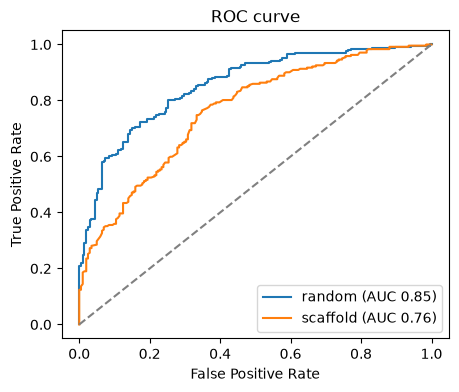

In [8]:
train.plot_roc(results)

## 5. Sanity checks

These decide what you can claim about the model. Note the numbers down.
Both need SMILES, so they are skipped automatically without them.

### 5a. Is the model better than a similarity search?

Baseline: score each test compound by how similar it is to the nearest known
active. If the model barely beats this, it mostly learned "looks like a known
active" rather than anything about the chemistry. Worth reporting either way.

In [9]:
if HAS_SMILES:
    sim = train.similarity_baseline(best)
    combo = train.combined_baseline(best, sim)
else:
    print("Skipped: needs a SMILES column. Note this on the limitations slide.")

Similarity baseline  ROC-AUC: 0.671 | PR-AUC: 0.696
Model                ROC-AUC: 0.762 | PR-AUC: 0.798
Combined ROC-AUC: 0.752 | PR-AUC: 0.792


### 5b. Where does the model actually work?

Test AUC split by structural similarity to the training set. The lowest bin
predicts how the model will behave on unfamiliar plant metabolites, which is
the number that matters for the project.

In [10]:
if HAS_SMILES:
    bins = train.reliability_bins(best)
else:
    print("Skipped: needs a SMILES column.")

max Tanimoto to train   n   AUC
       (0.146, 0.455] 111 0.619
       (0.455, 0.596] 112 0.721
        (0.596, 0.71] 109 0.828
          (0.71, 1.0] 111 0.874


## 6. Save

Saves the model together with the exact feature column order, plus the training
SMILES when available (needed for the reliability flag at prediction time).

`tune_cutoff=True` picks the 0/1 threshold by cross-validation on the training
data instead of defaulting to 0.5. The test set stays untouched.

In [11]:
train.save_model(best, tune_cutoff=True)

Tuned cutoff: 0.54 (CV MCC 0.434)
Saved: C:\Users\daria\workspace\0ethnohack\ethnohack\src\ethnohack\lox5_model\5lox_model.joblib (cutoff 0.54, 62 features)
Saved: C:\Users\daria\workspace\0ethnohack\ethnohack\datasets_preparation\train_smiles_5lox.csv (1771 training SMILES)


## 7. Check the saved model loads

`featurize` recomputes the descriptors from SMILES, so this also proves the
prediction path works end to end.

In [12]:
import ethnohack.lox5_model.lox5_model_api as lox

lox.reset_cache()
lox.model_info()

lox.predict(["CC(=O)Oc1ccccc1C(=O)O", "CC(C)Cc1ccc(cc1)C(C)C(=O)O"])  # aspirin, ibuprofen

features : 62 descriptor columns
split    : scaffold
cutoff   : 0.54
prevalence  : 0.546
pr_auc      : 0.798
roc_auc     : 0.762
mcc         : 0.337
precision   : 0.727
recall      : 0.616
f1          : 0.667
reliability flag: available


,smiles,proba,active,max_sim_train,in_domain
0,CC(=O)Oc1ccccc1C(=O)O,0.278,0.0,0.365854,False
1,CC(C)Cc1ccc(cc1)C(C)C(=O)O,0.046,0.0,1.000000,True


---

## Reading the results

**Compare PR-AUC against the prevalence**, not against 0. Prevalence is the
share of actives, which is what random guessing already achieves.

**The probabilities are a ranking, not a verdict.** Use them to compare and
sort compounds, not to declare one active.

**Filter to `in_domain == True`** before drawing conclusions or running SHAP,
where that column is available.

## For the 5-LOX model

Point the constants at the 5-LOX paths and rerun this notebook unchanged.

---

## 8. Explain the model (TreeSHAP)

SHAP splits each prediction into contributions of the individual features
(fingerprint bits and any extra descriptors). Positive values push toward
active, negative toward inactive.

Uses the saved model from section 7, so the features match the training exactly.

In [13]:
import ethnohack.explainer as xai

model = lox.load_model()

# fingerprint bits must come first, extra features after (needed for bit drawing)
xai.check_feature_layout(lox.feature_names(), model, lox.load_bundle())

Descriptor model: 62 features (50 fragment counts, 12 other descriptors)


'descriptor'

### 8a. Global view: which features drive the model

With `ONLY_IN_DOMAIN = True` only test molecules similar enough to the training
data are used, because SHAP on unfamiliar molecules explains unreliable predictions.

289 of 443 test molecules used


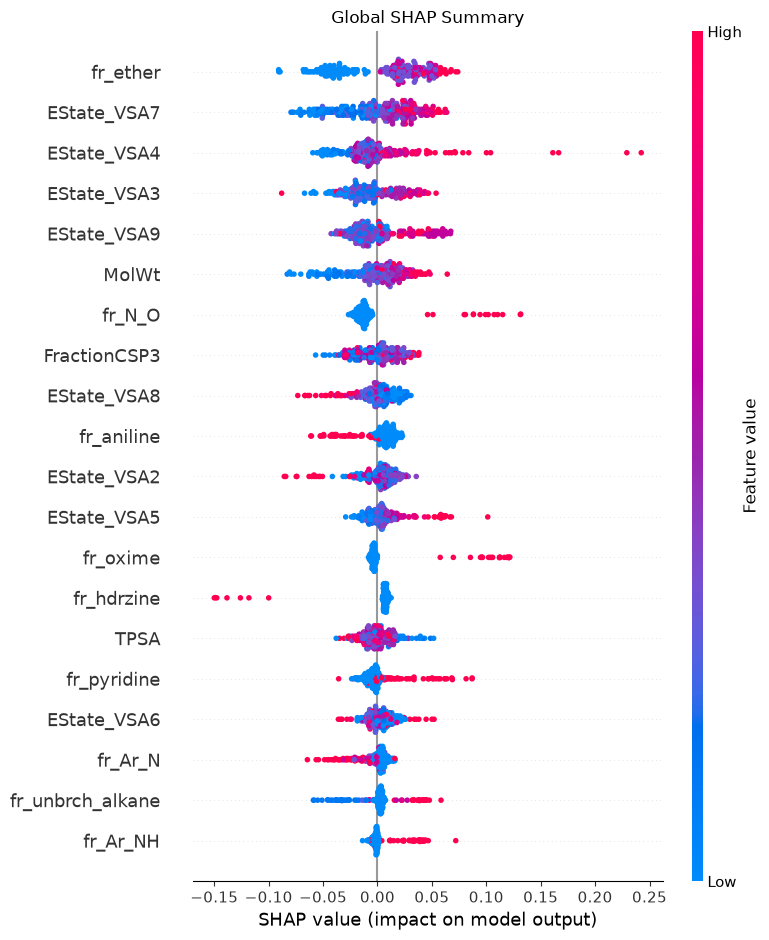

In [14]:
test_smiles = best["test_df"]["smiles"]
in_domain = lox.predict(test_smiles)["in_domain"].to_numpy(dtype=bool)
use = in_domain | (not ONLY_IN_DOMAIN)
print(f"{use.sum()} of {len(use)} test molecules used")

X_te = lox.featurize(test_smiles)[use]

# fingerprint bits get a substructure hint in their name for the plots
feature_names = xai.readable_feature_names(lox.feature_names(), test_smiles[use])

shap_matrix, X_shap = xai.global_shap(
    model, X_te, TARGET_CLASS, n_max=SHAP_MAX_MOLECULES
)
xai.plot_global_shap(shap_matrix, X_shap, feature_names)

In [15]:
top_features = xai.top_bits_table(shap_matrix, X_shap, feature_names)
top_features

,feature_index,kind,feature,mean_abs_shap,mean_shap_when_present,pushes_toward,share_of_molecules
0,34,fragment count,fr_ether,0.035678,0.032555,active,0.657439
1,6,descriptor,EState_VSA7,0.026817,0.005223,active,0.823529
2,3,descriptor,EState_VSA4,0.021937,-0.000878,inactive,0.968858
3,2,descriptor,EState_VSA3,0.020188,-0.000989,inactive,0.889273
4,8,descriptor,EState_VSA9,0.019538,0.002544,active,0.875433
5,10,descriptor,MolWt,0.019370,-0.000342,inactive,1.000000
6,21,fragment count,fr_N_O,0.017528,0.087209,active,0.051903
7,9,descriptor,FractionCSP3,0.014804,0.001375,active,0.920415
8,7,descriptor,EState_VSA8,0.012426,-0.001539,inactive,0.840830
9,27,fragment count,fr_aniline,0.012187,-0.024974,inactive,0.162630


In [16]:
# most important fingerprint bit drawn as a substructure on a test molecule
top_bits = xai.top_bits_table(shap_matrix, X_shap, feature_names, n_top=1, fp_only=True)
xai.highlight_bit(top_bits["feature_index"].iloc[0], X_te, test_smiles[use])

Bit 34 is not present in the selected molecule.


### 8b. Local view: why single molecules get their prediction

Most confident hits and mistakes from the test set. Red = pushes toward active,
blue = pushes toward inactive. The waterfall starts at the average prediction
(base value) and ends at the model probability.

In [17]:
examples = xai.select_examples(best, mask=use)

# in_domain tells you whether each prediction can be trusted
lox.predict([smiles for smiles, _, _ in examples.values()])

,smiles,proba,active,max_sim_train,in_domain
0,O=C(O)C=NOC(c1ccc(OCc2ccc3ccccc3n2)cc1)C1C2CC3...,0.982,1.0,0.734375,True
1,O=C1CCN(c2cccc(Cl)c2)N1,0.034,0.0,0.621622,True
2,O=C1CCN(c2ccc(Cl)cc2)N1,0.024,0.0,0.800000,True
3,Cc1ccc2nc(-c3ccc(OCC4CCN(C(=O)Nc5ccc(Cl)cc5)CC...,0.828,1.0,0.579545,True



##### True active (most confident) | True Label: 1 | Model Probability: 0.982
SMILES: O=C(O)C=NOC(c1ccc(OCc2ccc3ccccc3n2)cc1)C1C2CC3CC(C2)CC1C3
Base value: 0.500 | Model probability: 0.982
=== Top 2 contributing features ===
fr_oxime                     | value    1.000 | SHAP +0.112741 | fragment count
fr_pyridine                  | value    1.000 | SHAP +0.061660 | fragment count

=== Drawn on the structure (strongest localisable) ===
fr_oxime                     | SHAP +0.112741 | 1x | red (active)
fr_pyridine                  | SHAP +0.061660 | 1x | red (active)


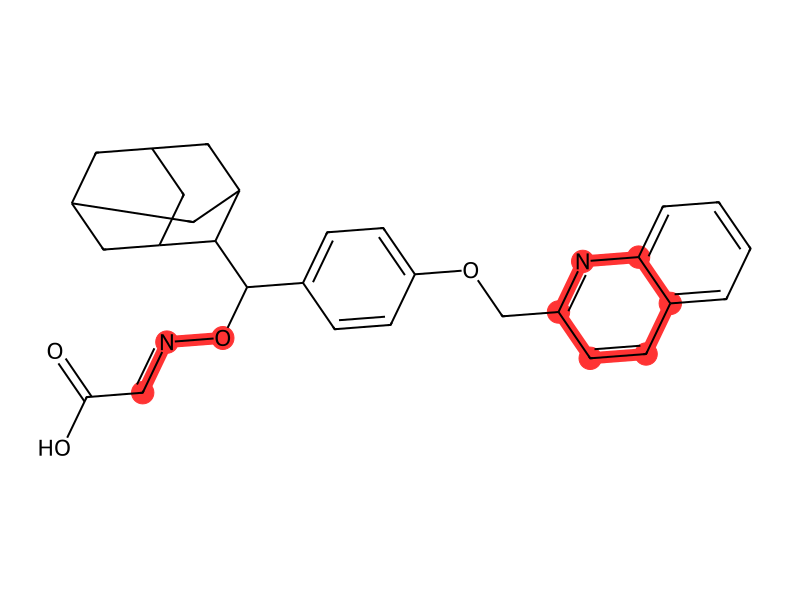

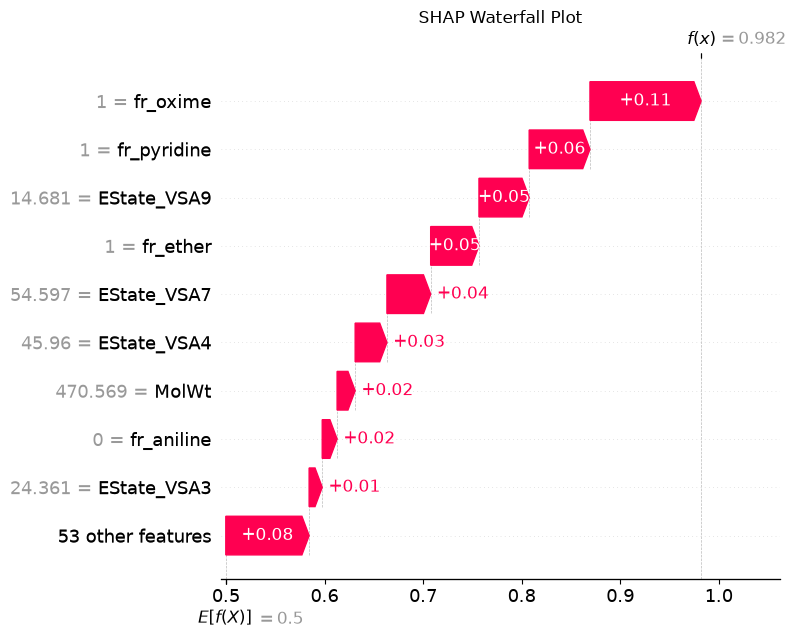


##### False negative (active predicted inactive) | True Label: 1 | Model Probability: 0.034
SMILES: O=C1CCN(c2cccc(Cl)c2)N1
Base value: 0.500 | Model probability: 0.034
=== Top 2 contributing features ===
fr_hdrzine                   | value    1.000 | SHAP -0.148871 | fragment count
MolWt                        | value  196.637 | SHAP -0.079399 | descriptor

=== Drawn on the structure (strongest localisable) ===
fr_hdrzine                   | SHAP -0.148871 | 1x | blue (inactive)
fr_aniline                   | SHAP -0.052662 | 1x | blue (inactive)


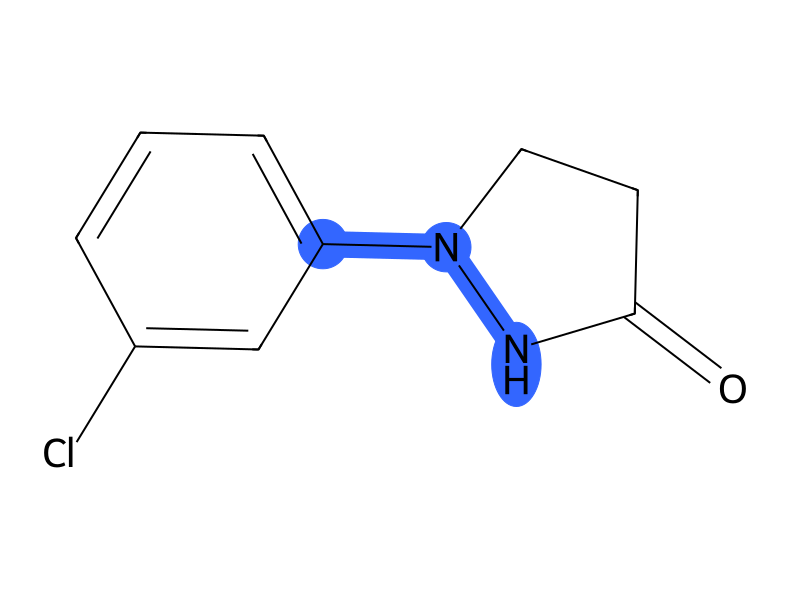

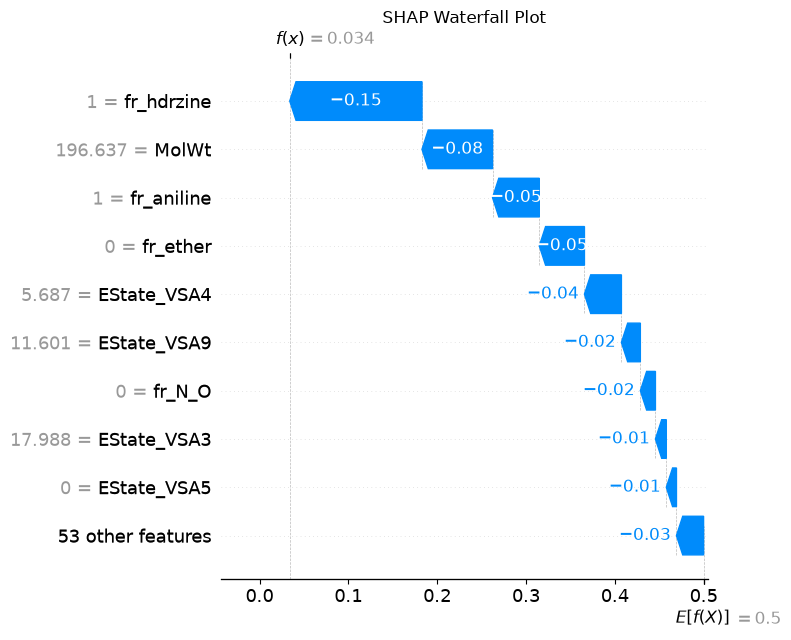


##### True inactive (most confident) | True Label: 0 | Model Probability: 0.024
SMILES: O=C1CCN(c2ccc(Cl)cc2)N1
Base value: 0.500 | Model probability: 0.024
=== Top 2 contributing features ===
fr_hdrzine                   | value    1.000 | SHAP -0.147693 | fragment count
MolWt                        | value  196.637 | SHAP -0.080738 | descriptor

=== Drawn on the structure (strongest localisable) ===
fr_hdrzine                   | SHAP -0.147693 | 1x | blue (inactive)
fr_aniline                   | SHAP -0.051506 | 1x | blue (inactive)


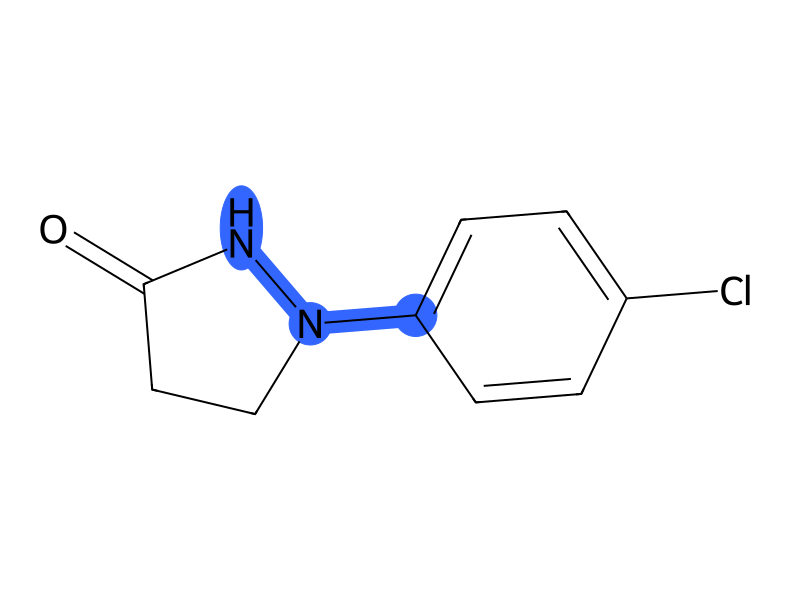

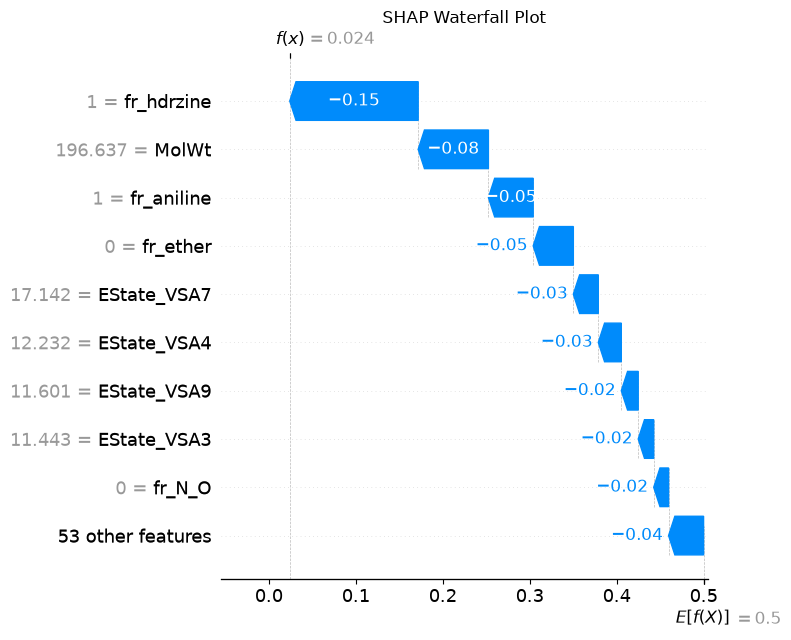


##### False positive (inactive predicted active) | True Label: 0 | Model Probability: 0.828
SMILES: Cc1ccc2nc(-c3ccc(OCC4CCN(C(=O)Nc5ccc(Cl)cc5)CC4)cc3)c(NC3CCCCC3)n2c1
Base value: 0.500 | Model probability: 0.828
=== Top 2 contributing features ===
EState_VSA4                  | value   60.090 | SHAP +0.078480 | descriptor
fr_pyridine                  | value    1.000 | SHAP +0.062277 | fragment count

=== Drawn on the structure (strongest localisable) ===
fr_pyridine                  | SHAP +0.062277 | 1x | red (active)
fr_ether                     | SHAP +0.038154 | 1x | red (active)


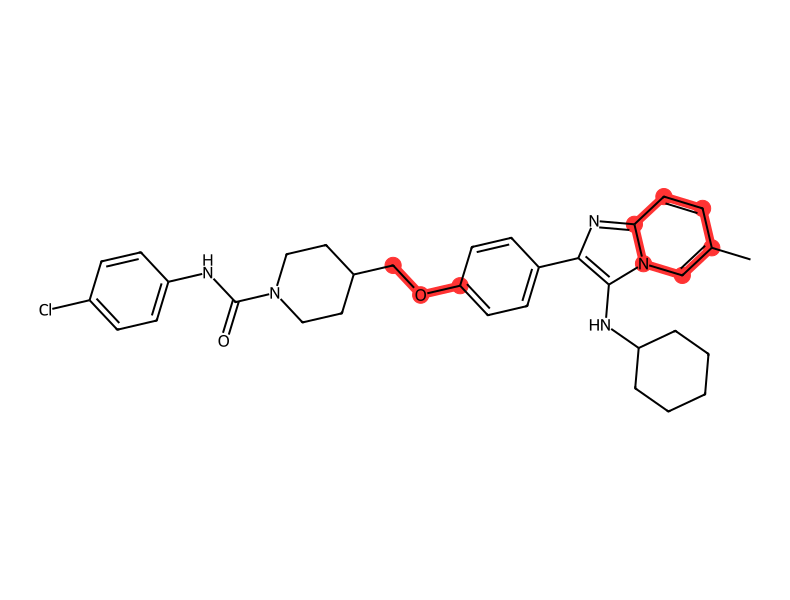

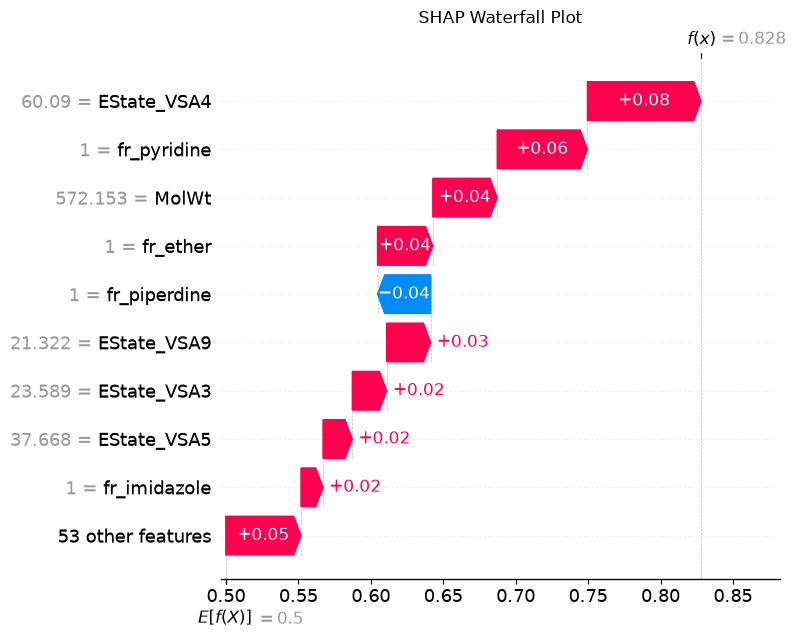

In [18]:
for name, (smiles, proba, label) in examples.items():
    print(f"\n##### {name} | True Label: {label} | Model Probability: {proba:.3f}")
    xai.explain_molecule(
        smiles,
        model,
        target_class=TARGET_CLASS,
        feature_names=feature_names,
        featurizer=lox.featurize,
    )

## 9. Screen COCONUT natural products

Scores natural products from COCONUT with the saved model, checks whether each
one is similar enough to the training data to be trusted, ranks them and
explains the top hits.

**Before you start:** download the COCONUT CSV from
https://coconut.naturalproducts.net/download and put it at `COCONUT_CSV` in
`constants.py`. Sections 6 and 7 must have run, because this uses the saved model.

In [20]:
import importlib
import ethnohack.constants
import ethnohack.coconut as coco
importlib.reload(ethnohack.constants)
from ethnohack.constants import PLANT_GENERA_FILE

In [21]:
# COCONUT screening
COCONUT_SMILES_COL = "canonical_smiles"
COCONUT_ID_COL = "identifier"
COCONUT_NAME_COL = "name"
COCONUT_N_MOLECULES = None  # random sample to test the workflow, None = all molecules
COCONUT_CHUNK_SIZE = 5000  # molecules scored per batch, lower = less memory
COCONUT_TOP_N = 50  # how many top-ranked molecules to list
COCONUT_N_EXPLAIN = 10  # how many of those to explain with SHAP
COCONUT_ORGANISM_COL = "organisms"   # check with coco.list_columns()

In [26]:
import ethnohack.lox5_model.lox5_preprocess as lox_prep

coco.list_columns()

genera = coco.load_plant_genera(PLANT_GENERA_FILE)
coconut, np_overlap = coco.prepare_coconut(
    plant_genera=genera,
    organism_col=COCONUT_ORGANISM_COL,
    smiles_col=COCONUT_SMILES_COL,
    id_col=COCONUT_ID_COL,
    name_col=COCONUT_NAME_COL,
    n_max=COCONUT_N_MOLECULES,
    prep=lox_prep,     
)
coconut.head()

['identifier', 'canonical_smiles', 'standard_inchi', 'standard_inchi_key', 'name', 'iupac_name', 'annotation_level', 'total_atom_count', 'heavy_atom_count', 'molecular_weight', 'exact_molecular_weight', 'molecular_formula', 'alogp', 'topological_polar_surface_area', 'rotatable_bond_count', 'hydrogen_bond_acceptors', 'hydrogen_bond_donors', 'hydrogen_bond_acceptors_lipinski', 'hydrogen_bond_donors_lipinski', 'lipinski_rule_of_five_violations', 'aromatic_rings_count', 'qed_drug_likeliness', 'formal_charge', 'fractioncsp3', 'number_of_minimal_rings', 'van_der_walls_volume', 'contains_sugar', 'contains_ring_sugars', 'contains_linear_sugars', 'murcko_framework', 'np_likeness', 'chemical_class', 'chemical_sub_class', 'chemical_super_class', 'direct_parent_classification', 'np_classifier_pathway', 'np_classifier_superclass', 'np_classifier_class', 'np_classifier_is_glycoside', 'organisms', 'collections', 'dois', 'synonyms', 'cas']
Possible organism columns: ['organisms']
Plant genera loaded: 

Standardizing: 100%|██████████| 148/148 [12:41<00:00,  5.14s/it]


Standardized: 738788 kept | 5 unusable removed
With organism annotation: 273547 (37.0%) | with a plant species: 142952
Most frequent genera NOT matched as plants:
Streptomyces (36415), Artemisia (12243), Aspergillus (10758), Penicillium (9842), Astragalus (3973), Pinus (3966), Isodon (3816), Angelica (3500), Annona (3106), Achillea (2971), Homo (2849), Corydalis (2615), Ganoderma (2612), Fusarium (2578), Thymus (2384)
Collapsed duplicates: 738788 -> 487497
Plant compounds: 100151
Raw: 2320 rows, 66 columns


Standardizing: 100%|██████████| 1/1 [00:05<00:00,  5.95s/it]

Standardized: 2320 kept | 0 unusable removed
Training overlap: 103 removed from screening | 100048 remain


,id,name,smiles,organisms,std_smiles,parent_id,plants,n_plant_species,is_plant,n_variants,all_ids
0,CNP0599238.1,"N-[1-[(4aR)-1,3,3,4a-tetramethyl-4,7-dioxo-2H-...",CC(=O)NC(C)(C)CC1=C[C@@]2(C)C(=O)C(C)(C)NC(C)=...,Anacyclus pyrethrum,CC(=O)NC(C)(C)CC1=CC2(C)C(=O)C(C)(C)NC(C)=C2C1=O,CNP0599238,Anacyclus pyrethrum,1,True,1,CNP0599238.1
1,CNP0602397.0,octadecadienamide,CCCCCCCCCCCCCC=CC=CC(N)=O,Piper longum,CCCCCCCCCCCCCC=CC=CC(N)=O,CNP0602397,Piper longum,1,True,1,CNP0602397.0
2,CNP0154298.0,"6-hydroxy-1,1,4,7-tetramethyl-naphtho[2,1-b]ox...",CC1=C(O)C(=O)C2=C(C)C=C3OC(C)(C)C3=C2C1=O,Amentotaxus formosana,CC1=C(O)C(=O)c2c(C)cc3c(c2C1=O)C(C)(C)O3,CNP0154298,Amentotaxus formosana,1,True,1,CNP0154298.0
3,CNP0499294.0,NaN,COC1=CC(O)=C2C(=C1)CCC1=CC(O)=C(C3=C(OC)C=C(O)...,Centaurea pabotii|Clibadium glabrescens|Climac...,COc1cc(O)c2c(c1)CCc1cc(O)c(-c3c(OC)cc(O)c4c3CC...,CNP0499294,Centaurea pabotii|Clibadium glabrescens|Eria b...,8,True,1,CNP0499294.0
4,CNP0155931.0,Glypetelotine,CSC(=O)N(C)CCC1=CNC2=CC=CC=C12,Glycosmis petelotii,CSC(=O)N(C)CCc1c[nH]c2ccccc12,CNP0155931,Glycosmis petelotii,1,True,1,CNP0155931.0


### 9a. Score

Includes the reliability check (`max_sim_train`, `in_domain`). This is the slow
part, because every molecule is compared with the whole training set. Start with
the sample from cell 1, then set `COCONUT_N_MOLECULES = None` for the full run.

In [ ]:
scored = coco.score_coconut(
    coconut,
    chunk_size=COCONUT_CHUNK_SIZE,
    api=coco.lox5_api,                            
    confidence_edges=coco.CONFIDENCE_EDGES_LOX5,  
)
coco.summarize(scored)

Scoring:   0%|          | 0/21 [00:00<?, ?it/s]c:\Users\daria\workspace\0ethnohack\ethnohack\.venv\Lib\site-packages\pandas\core\dtypes\astype.py:141: RuntimeWarning: overflow encountered in cast
  return arr.astype(dtype, copy=copy)
Scoring:   5%|▍         | 1/21 [01:18<26:15, 78.77s/it]

In [ ]:
LOX5_SIM_FLOOR = 0.49   
cand = scored[scored["max_sim_train"] >= LOX5_SIM_FLOOR].reset_index(drop=True)
cand = coco.flag_alerts(cand)

### 9b. Top hits

Only `in_domain` molecules are ranked, because predictions on molecules far
from the training data are much less reliable. The probability is a ranking,
not a verdict: use it to compare and prioritise, not to call a compound active.

In [ ]:
hits = coco.top_hits(
    cand,
    n=COCONUT_TOP_N,
    in_domain_only=False,
    min_confidence="medium",
    exclude_alerts=True,
)
hits

In [ ]:
coco.save_scores(scored)

### 9c. Explain the top hits

Red = pushes toward active, blue = pushes toward inactive. The waterfall starts
at the average prediction (base value) and ends at the model probability.

In [ ]:
import ethnohack.explainer as xai

model = lox.load_model()
top = hits.head(COCONUT_N_EXPLAIN)

# fingerprint bits get a substructure hint in their name for the plots
coconut_names = xai.readable_feature_names(lox.feature_names(), top["std_smiles"])

for _, row in top.iterrows():
    print(f"\n##### {row['id']} | {row['name']} | model probability: {row['proba']:.3f}")
    xai.explain_molecule(
        row["std_smiles"],
        model,
        target_class=TARGET_CLASS,
        feature_names=coconut_names,
        featurizer=lox.featurize,
    )